# 1. Coleta e análise de dados

Nessa seção, usaremos o dataset California Housing do sklearn.datasets e analisaremos quais features são as mais relevantes para treinar um modelo usando regressão linear e, depois, vamos observar o gráfico entre elas e o target "MedHouseVal".

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)                                                                                                                      
data = housing.frame

data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude"]
y = data["MedHouseVal"]

for feature in features:
    x = data[feature]
    x = np.abs(x)
    print(feature)
    print("x     : ", np.corrcoef(x, y)[0, 1])
    print("x²    : ", np.corrcoef(x**2, y)[0, 1])
    print("log x : ", np.corrcoef(np.log(x), y)[0, 1])
    print(30 * "-")

MedInc
x     :  0.6880752079585478
x²    :  0.6245141174002229
log x :  0.651807308718347
------------------------------
HouseAge
x     :  0.1056234124932099
x²    :  0.11995529370313147
log x :  0.07646671767302844
------------------------------
AveRooms
x     :  0.15194828974145788
x²    :  0.028310459575205442
log x :  0.24038552323536724
------------------------------
AveBedrms
x     :  -0.046700512969486865
x²    :  -0.006406577263087941
log x :  -0.0858376739957538
------------------------------
Population
x     :  -0.02464967888889488
x²    :  -0.010088586444325575
log x :  -0.021157815999741886
------------------------------
AveOccup
x     :  -0.02373741295613436
x²    :  -0.004640443524783674
log x :  -0.25586232074238313
------------------------------
Latitude
x     :  -0.1441602768746593
x²    :  -0.147864958840257
log x :  -0.14051896737610298
------------------------------
Longitude
x     :  0.04596661511797851
x²    :  0.045776236921367695
log x :  0.04616861868107999
---

In [3]:
data["log_AveRooms"] = np.log(data["AveRooms"])
data["log_AveOccup"] = np.log(data["AveOccup"])
data = data[["MedInc", "log_AveOccup", "log_AveRooms", "MedHouseVal"]]
data

,MedInc,log_AveOccup,log_AveRooms,MedHouseVal
0,8.3252,0.938270,1.943640,4.526
1,8.3014,0.746613,1.830682,3.585
2,7.2574,1.030426,2.114825,3.521
3,5.6431,0.935287,1.760845,3.413
4,3.8462,0.779998,1.837665,3.422
...,...,...,...,...
20635,1.5603,0.940244,1.618488,0.781
20636,2.5568,1.138732,1.810587,0.771
20637,1.7000,0.843993,1.649724,0.923
20638,1.8672,0.752929,1.673260,0.847


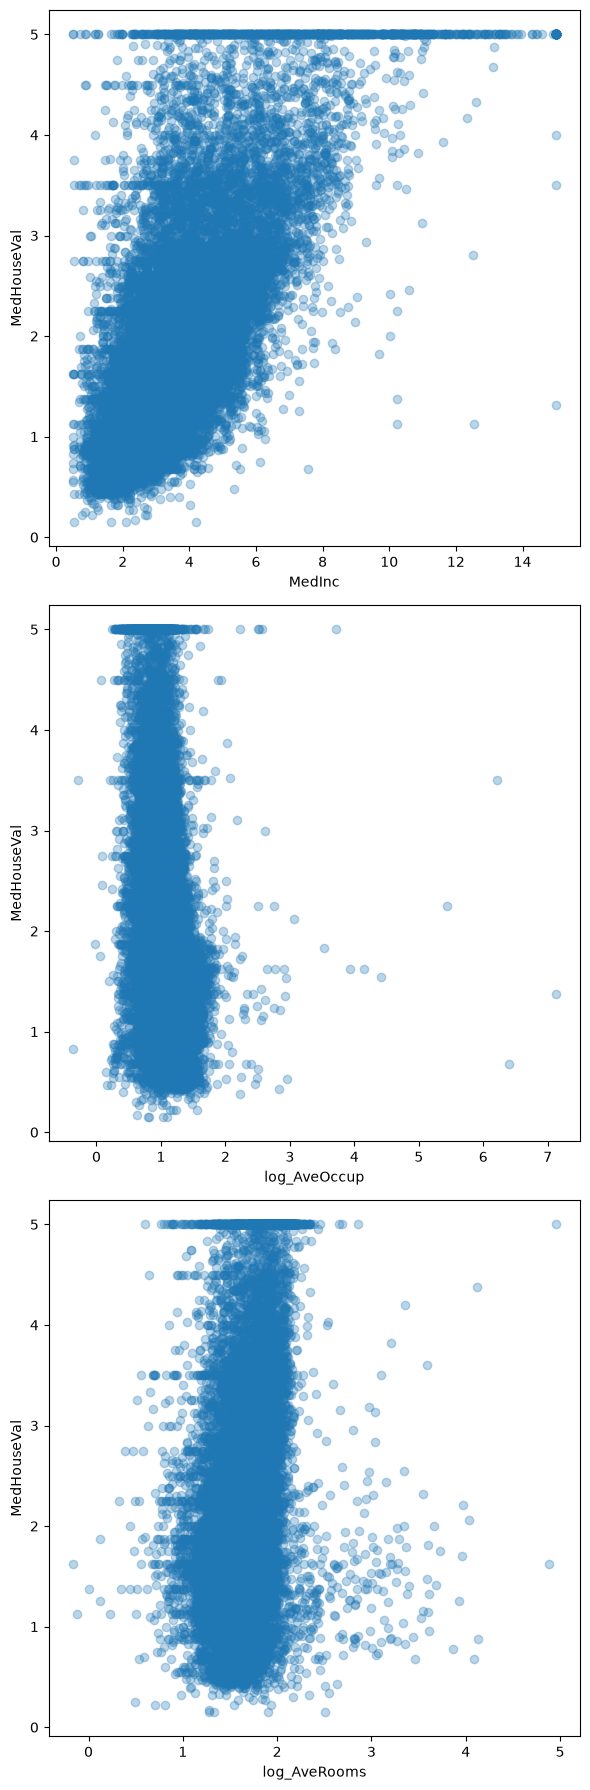

In [14]:
y = data["MedHouseVal"]

fig, ax = plt.subplots(3, 1, figsize = (6, 18))

ax[0].scatter(data["MedInc"], y, alpha=0.3)
ax[0].set_xlabel("MedInc")
ax[0].set_ylabel("MedHouseVal")

ax[1].scatter(data["log_AveOccup"], y, alpha=0.3)
ax[1].set_xlabel("log_AveOccup")
ax[1].set_ylabel("MedHouseVal")

ax[2].scatter(data["log_AveRooms"], y, alpha=0.3)
ax[2].set_xlabel("log_AveRooms")
ax[2].set_ylabel("MedHouseVal")

plt.tight_layout()
plt.show()

### Observações
Observamos a correlação de Pearson (linear, quadrática e logarítmica) entre cada feature e o target "MedHouseVal" para decidir quais delas serão selecionadas para o treinamento do modelo na próxima seção (quanto maior, melhor é a feature para o trenamento).

# 2. Treinamento do modelo
Dividiremos o dataset em train (conjunto de treino, usado para ajustar os coeficientes) e test (conjunto de teste, reservado para avaliar o modelo em dados não vistos) e aplicaremos a regressão linear. Depois disso, vamos substituir por 0 todos os valores negativos de preço.

In [4]:
from sklearn.model_selection import train_test_split

X = data.drop(columns="MedHouseVal")
y = data["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

print("X_train:", X_train.shape, "\n"
      "X_test:",  X_test.shape,  "\n"
      "y_train:", y_train.shape, "\n"
      "y_test:",  y_test.shape)

X_train: (14448, 3) 
X_test: (6192, 3) 
y_train: (14448,) 
y_test: (6192,)


In [5]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()
reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0.48,-1. ,-0.85]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['MedInc','log_AveOccup','log_AveRooms']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.642
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [6]:
predictions = reg.predict(X_test)
predictions

array([0.87848416, 1.50368974, 2.84316897, ..., 2.34864241, 1.68785126,
       2.12456982], shape=(6192,))

# 3. Avaliação de desempenho do modelo
Nessa parte, analisaremos o quão bem o modelo consegue prever o MedHouseVal usando o erro absoluto médio (MAE; variável error). Também vamos analisar como a regressão linear se comporta nos gráficos de cada feature.

In [9]:
from sklearn.metrics import mean_absolute_error

error = mean_absolute_error(y_test, predictions)
error

0.5663933029201227

In [10]:
data.describe()["MedHouseVal"]

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64